In [1]:
import numpy as np
from skimage import io
import matplotlib.pyplot as plt
from skimage.transform import warp, EuclideanTransform, ProjectiveTransform, AffineTransform, swirl

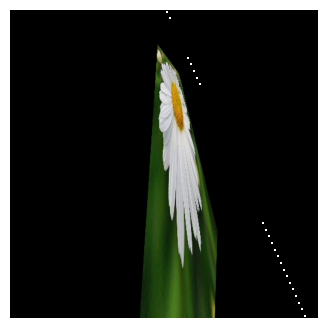

In [ ]:
# Source image
basename = "daisy"
src = io.imread(f"../../src/figs/{basename}.png")

# Translation
t = EuclideanTransform(rotation=0, translation=(25, 100))
translation = warp(src, t.inverse)

# Rotation
t = EuclideanTransform(rotation=np.pi/6, translation=(0, 0))
rotation = warp(src, t.inverse)

# Euclidean transform
t = EuclideanTransform(rotation=np.pi/4, translation=(250, 50))
euclidean = warp(src, t.inverse)

# Affine transform (scale)
t = AffineTransform(scale=.7, shear=0, rotation=0, translation=(0,0))
scale = warp(src, t.inverse)

# Affine transform (shear)
t = AffineTransform(scale=1, shear=.5, rotation=0, translation=(100,0))
shear = warp(src, t.inverse)

# Affine transform (scale+shear)
t = AffineTransform(scale=.7, shear=.5, rotation=0, translation=(100,0))
affine = warp(src, t.inverse)

# Projective transform
matrix = np.array([ [0.35, -0.50, 245], [0.2,  0.04,  57], [0.0004, -0.002,   1.0000] ])
t = ProjectiveTransform(matrix)
projective = warp(src, t.inverse)

# Non linear deformation
non_linear = swirl(src, rotation=0, strength=10, radius=src.shape[0])

# Display
images = [
    [src, "original"],
    [translation, "translation"],
    [rotation, "rotation"],
    [euclidean, "euclidean"],
    [scale, "scale"],
    [shear, "shear"],
    [affine, "affine"],
    [projective, "projective"],
    [non_linear, "non-linear"],
]
for img, deformation in images:
    fig = plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis('off')
    plt.savefig(f"{basename}-{deformation}.png", bbox_inches="tight")
    plt.show()